WEBSITE TRAFFIC DATA
            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2025-01-01        1025              603        51.25
2025-01-02        1076              679        50.63
2025-01-03        1140              643        50.78
2025-01-04        1135              625        52.27
2025-01-05         965              574        48.25

Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 90 entries, 2025-01-01 to 2025-03-31
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Page_Views       90 non-null     int64  
 1   Unique_Visitors  90 non-null     int64  
 2   Bounce_Rate      90 non-null     float64
dtypes: float64(1), int64(2)
memory usage: 2.8 KB
None

Missing Values:
Page_Views         0
Unique_Visitors    0
Bounce_Rate        0
dtype: int64

Missing Values After Interpolation:
Page_Views         0
Unique_Visitors    0
Bounce_Rate       

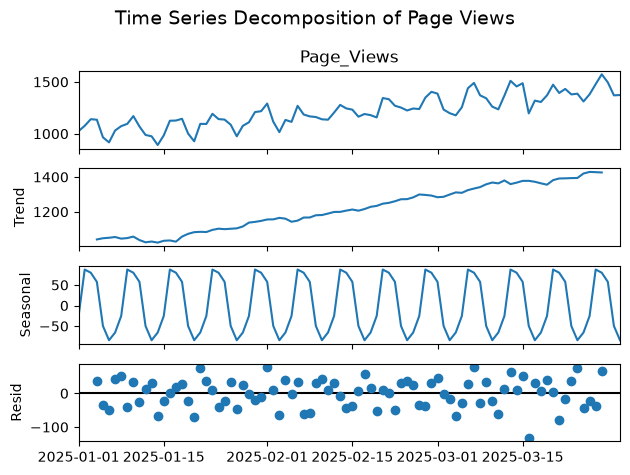

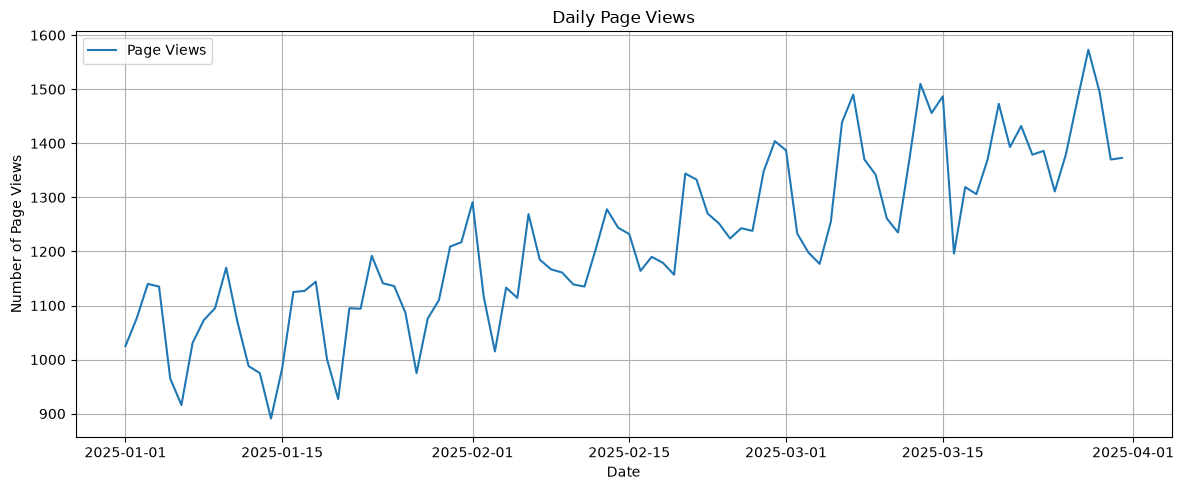

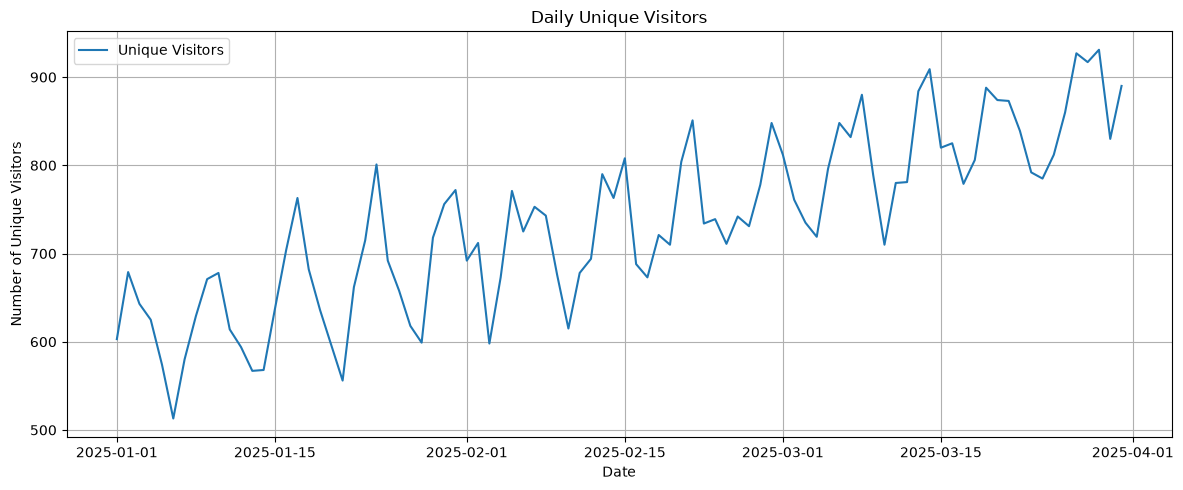

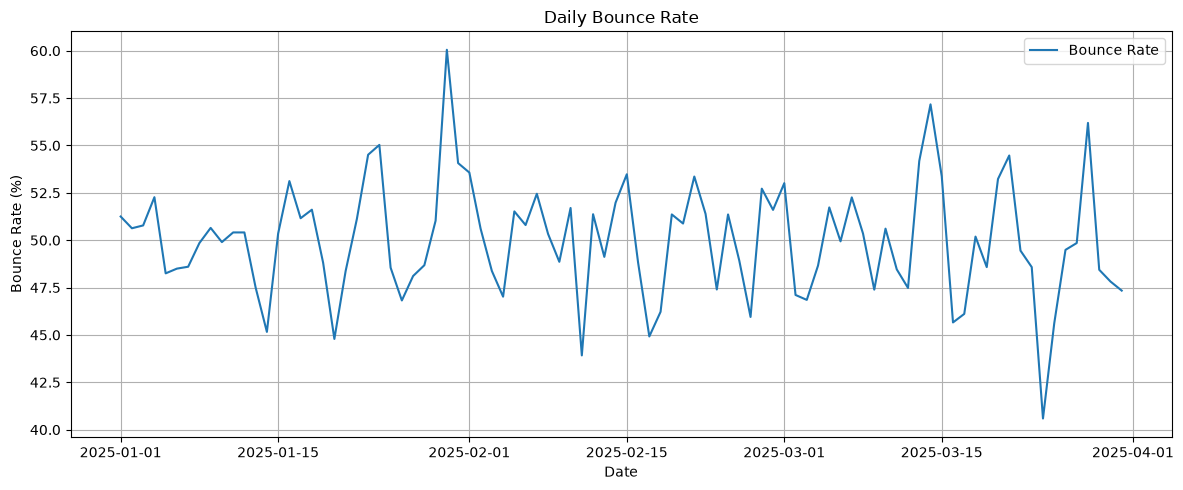

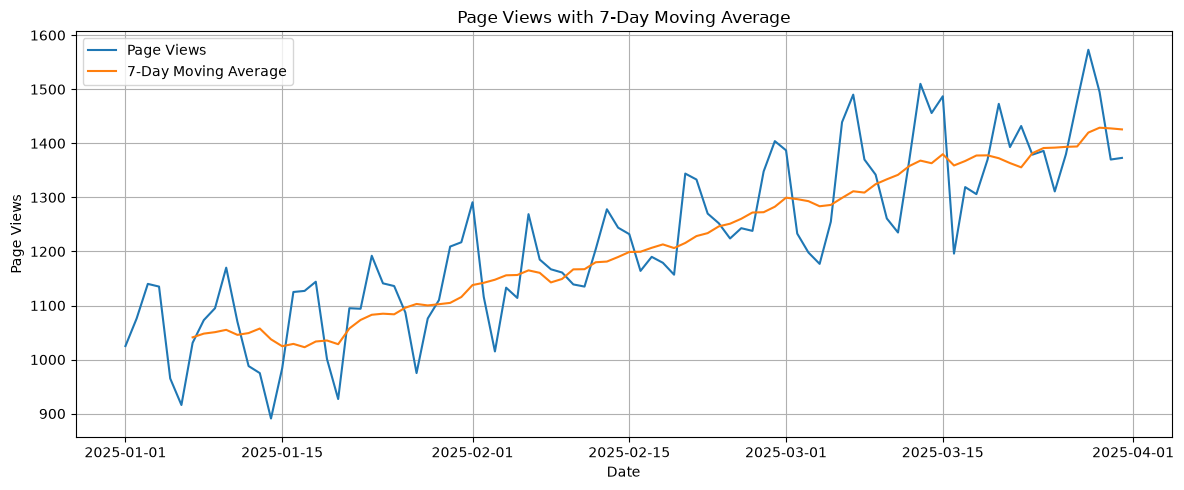

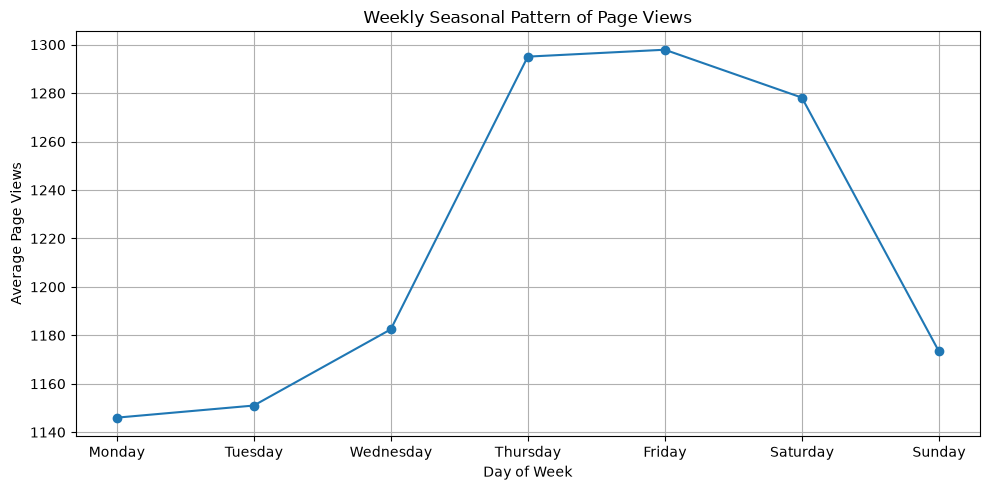


ANOMALIES DETECTED
No anomalies detected.


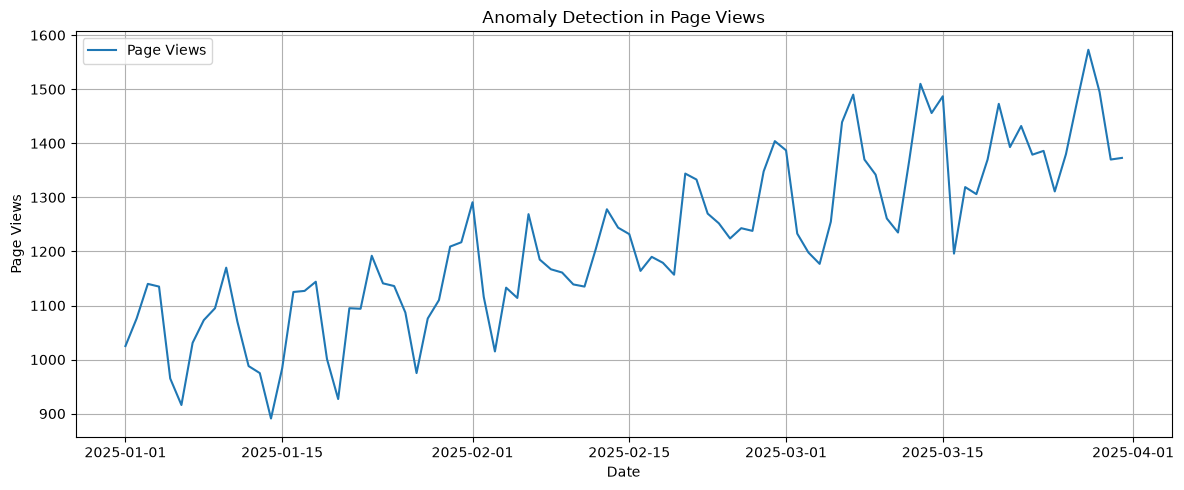


FINAL DATASET
            Page_Views  Unique_Visitors  Bounce_Rate  Page_Views_MA  \
Date                                                                  
2025-01-01        1025              603        51.25            NaN   
2025-01-02        1076              679        50.63            NaN   
2025-01-03        1140              643        50.78            NaN   
2025-01-04        1135              625        52.27            NaN   
2025-01-05         965              574        48.25            NaN   
2025-01-06         916              513        48.50            NaN   
2025-01-07        1031              580        48.60    1041.142857   
2025-01-08        1073              629        49.85    1048.000000   
2025-01-09        1095              671        50.65    1050.714286   
2025-01-10        1170              678        49.90    1055.000000   

            Page_Views_Z  
Date                      
2025-01-01     -1.253630  
2025-01-02     -0.923140  
2025-01-03     -0.508407

In [1]:
# ============================================================
# EXPERIMENT 6: TIME SERIES ANALYSIS OF WEBSITE TRAFFIC
# ============================================================

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


# ============================================================
# 1. CREATE WEBSITE TRAFFIC DATASET
# ============================================================

# Create dates for 90 days
dates = pd.date_range(start='2025-01-01', periods=90, freq='D')

# Set random seed so results are reproducible
np.random.seed(42)

# Generate Page Views
page_views = (
    1000
    + np.arange(90) * 5
    + 100 * np.sin(2 * np.pi * np.arange(90) / 7)
    + np.random.normal(0, 50, 90)
)

# Generate Unique Visitors
unique_visitors = (
    600
    + np.arange(90) * 3
    + 60 * np.sin(2 * np.pi * np.arange(90) / 7)
    + np.random.normal(0, 30, 90)
)

# Generate Bounce Rate
bounce_rate = (
    50
    + 3 * np.sin(2 * np.pi * np.arange(90) / 7)
    + np.random.normal(0, 2, 90)
)

# Create DataFrame
data = pd.DataFrame({
    'Date': dates,
    'Page_Views': page_views,
    'Unique_Visitors': unique_visitors,
    'Bounce_Rate': bounce_rate
})

# Set Date as index
data.set_index('Date', inplace=True)

# Round values
data['Page_Views'] = data['Page_Views'].round().astype(int)
data['Unique_Visitors'] = data['Unique_Visitors'].round().astype(int)
data['Bounce_Rate'] = data['Bounce_Rate'].round(2)


# ============================================================
# 2. DISPLAY DATA
# ============================================================

print("WEBSITE TRAFFIC DATA")
print("====================")
print(data.head())

print("\nDataset Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())


# ============================================================
# 3. HANDLE MISSING VALUES
# ============================================================

# Interpolate missing values
data.interpolate(method='linear', inplace=True)

print("\nMissing Values After Interpolation:")
print(data.isnull().sum())


# ============================================================
# 4. TIME SERIES DECOMPOSITION
# ============================================================

# Decompose Page Views
decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=7
)

# Display decomposition
decomposition.plot()

plt.suptitle(
    'Time Series Decomposition of Page Views',
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. PLOT PAGE VIEWS
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Page_Views'],
    label='Page Views'
)

plt.title('Daily Page Views')
plt.xlabel('Date')
plt.ylabel('Number of Page Views')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. PLOT UNIQUE VISITORS
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Unique_Visitors'],
    label='Unique Visitors'
)

plt.title('Daily Unique Visitors')
plt.xlabel('Date')
plt.ylabel('Number of Unique Visitors')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. PLOT BOUNCE RATE
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Bounce_Rate'],
    label='Bounce Rate'
)

plt.title('Daily Bounce Rate')
plt.xlabel('Date')
plt.ylabel('Bounce Rate (%)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. MOVING AVERAGE
# ============================================================

# Calculate 7-day moving average
data['Page_Views_MA'] = data['Page_Views'].rolling(
    window=7
).mean()

# Plot original and moving average
plt.figure(figsize=(12, 5))

plt.plot(
    data.index,
    data['Page_Views'],
    label='Page Views'
)

plt.plot(
    data.index,
    data['Page_Views_MA'],
    label='7-Day Moving Average'
)

plt.title('Page Views with 7-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Page Views')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. SEASONAL ANALYSIS
# ============================================================

# Create Day of Week column
data['Day'] = data.index.day_name()

# Order of days
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

# Calculate average page views for each day
seasonal_data = data.groupby('Day')['Page_Views'].mean()

# Arrange days in correct order
seasonal_data = seasonal_data.reindex(day_order)

# Plot seasonal pattern
plt.figure(figsize=(10, 5))

plt.plot(
    seasonal_data.index,
    seasonal_data.values,
    marker='o'
)

plt.title('Weekly Seasonal Pattern of Page Views')
plt.xlabel('Day of Week')
plt.ylabel('Average Page Views')

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. ANOMALY DETECTION USING Z-SCORE
# ============================================================

# Calculate mean
mean_page_views = data['Page_Views'].mean()

# Calculate standard deviation
std_page_views = data['Page_Views'].std()

# Calculate Z-score
data['Page_Views_Z'] = (
    (data['Page_Views'] - mean_page_views)
    / std_page_views
)

# Find anomalies
anomalies = data[
    data['Page_Views_Z'].abs() > 3
]

# Display anomalies
print("\nANOMALIES DETECTED")
print("==================")

if len(anomalies) == 0:
    print("No anomalies detected.")
else:
    print(
        anomalies[
            ['Page_Views', 'Page_Views_Z']
        ]
    )


# ============================================================
# 11. VISUALIZE ANOMALIES
# ============================================================

plt.figure(figsize=(12, 5))

# Plot Page Views
plt.plot(
    data.index,
    data['Page_Views'],
    label='Page Views'
)

# Plot anomalies
if len(anomalies) > 0:
    plt.scatter(
        anomalies.index,
        anomalies['Page_Views'],
        color='red',
        label='Anomalies',
        s=60
    )

plt.title('Anomaly Detection in Page Views')
plt.xlabel('Date')
plt.ylabel('Page Views')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 12. DISPLAY FINAL DATA
# ============================================================

print("\nFINAL DATASET")
print("=============")

print(
    data[
        [
            'Page_Views',
            'Unique_Visitors',
            'Bounce_Rate',
            'Page_Views_MA',
            'Page_Views_Z'
        ]
    ].head(10)
)

print("\nExperiment 6 completed successfully!")